# KION: исследование автоматических признаков

Ноутбук воспроизводит анализ завершённого эксперимента и прогнозы сохранённых
моделей. Обучение запрещено программно. Нужны локальные данные/кэши/модели:
при их отсутствии выполнение останавливается, а не запускает обучение.

Основной результат: auto NDCG@10 ≈ 0.15700, full ≈ 0.15729; преимущество
не подтверждено. Специальный отбор уступил одному фиксированному random
в диагностическом сравнении. Это не доказательство универсального преимущества random.
Метод и тестовый набор после оценки не меняются.

In [1]:
import os
from pathlib import Path
import sys, json, gc
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'autofeatures.toml').is_file(), 'Run from project root or notebooks/'
sys.path.insert(0, str(ROOT))
from kion_autofeatures.runtime import configure
configure(2)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from catboost import CatBoostRanker, CatBoost
from kion.io import sha256
from kion_autofeatures.config import ResearchConfig
from kion_autofeatures.final import verify, verify_frozen
from kion_autofeatures.baseline import Baseline, attach_features
from kion_autofeatures.grammar import enumerate_features, resolve_specs
from kion_autofeatures.engine import HistoryFeatures
from kion_autofeatures.model import predict_model
from kion.protocol import load_prepared, day_number
fit_attempts = []
def forbidden_fit(*args, **kwargs):
    fit_attempts.append('fit')
    raise RuntimeError('Training is disabled in this verification notebook')
CatBoostRanker.fit = forbidden_fit
CatBoost.fit = forbidden_fit
research = ResearchConfig.load(ROOT / 'autofeatures.toml')
D = research.results
def read(path):
    return json.loads(Path(path).read_text())
print({'python': sys.version.split()[0], 'threads': research.threads,
       'run': research.run_name, 'training': 'disabled'})

{'python': '3.14.7', 'threads': 2, 'run': 'main', 'training': 'disabled'}


## Зафиксированный эксперимент

Обучение baseline: 19/26 июля и 2 августа; внешняя валидация 9 августа;
финальное переобучение также включает 9 августа, тест 16–22 августа 2021.
Все исторические признаки используют даты строго раньше среза. KION хранит
последнюю дату пары, а не полный журнал просмотров. Метаданные статические.
Исходный тест baseline был известен до второй части — ограничение исследования.

In [2]:
for name in ('inputs', 'selection', 'validation', 'frozen', 'test',
             'test_intervals', 'test_verification', 'validation_verification'):
    assert (D / f'{name}.json').is_file(), f'Missing completed artifact: {name}'
frozen = verify_frozen(research)
baseline = Baseline(research)
original_test = read(ROOT / 'results/test_manifest.json')
record = read(D / 'test.json')
selection = read(D / 'selection.json')
assert record['test_evaluated'] and record['identity']['frozen_seal'] == frozen['seal']
model_paths = {'full': ROOT / original_test['models']['catboost']['path']}
model_paths.update({name: research.artifacts / 'test' / name / 'model.cbm'
                    for name in frozen['final_variants']})
unchanged_paths = [D / 'frozen.json', *model_paths.values()]
unchanged_paths += [research.artifacts / 'test' / n / 'fit.json' for n in frozen['final_variants']]
for path in unchanged_paths:
    assert path.is_file(), f'Missing saved artifact: {path}'
before = {str(p.relative_to(ROOT)): (sha256(p), p.stat().st_mtime_ns) for p in unchanged_paths}
print('Frozen seal:', frozen['seal'])
display(pd.DataFrame([record['snapshot_diagnostics']]))
print('Final training: 2,940,779 pairs / 14,704 queries; test: 2,284,830 pairs / 11,425 users')

Frozen seal: 8aa5502a0eba5ec202350035db8243174d70c3f845901c27f37821c0a7c5e956


,cold_active_users,cutoff,history_items,history_rows,history_users,target_rows,warm_active_users,warm_user_new_item_targets
0,5870,2021-08-16,9938,528842,94130,43779,11425,873


Final training: 2,940,779 pairs / 14,704 queries; test: 2,284,830 pairs / 11,425 users


## Внутренний выбор и состав признаков

S: 13 сигналов источников; R: 15 статических колонок; M: 54 ручных агрегата.
Auto = S+R+A (44), full = S+R+M (82); random = S+R+16 случайных агрегатов (44).
Грамматика 504 признака: 10 путей, 8 окон, count/sum/mean/max,
recency/share/trend. Два точных дубликата S исключены только на обучении.
Screen: 120 деревьев depth=6, обучающая PredictionValuesChange; префиксы
оцениваются на 1000 пользователях 2 августа. Выбирается минимальный размер
в пределах 0.0001 от лучшего. Внешняя валидация не выбирает новый набор.

In [3]:
assert len(enumerate_features()) == 504
assert len(selection['eligible']) == 502
assert len(selection['selected']) == len(selection['random']) == 16
assert not set(selection['selected']) & set(selection['random'])
prefixes = pd.DataFrame([{'A': p['size'], **p['metrics']} for p in selection['prefixes']])
display(prefixes)
from kion_autofeatures.search import choose_prefix
assert choose_prefix(selection['prefixes'], research.tie_tolerance)['size'] == selection['chosen_size'] == 16
display(pd.read_csv(D / 'selected_features.csv').astype(object).fillna('—'))
display(pd.DataFrame([read(D / 'selection_summary.json')['operations']]))

,A,candidate_recall@200,map@10,ndcg@10,recall@10,users
0,16,0.584969,0.109498,0.158236,0.231418,1000
1,32,0.584969,0.109884,0.158329,0.230902,1000
2,64,0.584969,0.104243,0.152643,0.227247,1000


,set,feature,path,operation,window,long_window,manual_semantic_equivalent
0,selected,auto__item__trend__10_60,item,trend,10,60.0,—
1,selected,auto__item__sum_log_dur__3,item,sum_log_dur,3,—,—
2,selected,auto__item__count__3,item,count,3,—,—
3,selected,auto__item_sex__sum_log_dur__3,item_sex,sum_log_dur,3,—,—
4,selected,auto__item_kids_flg__trend__10_60,item_kids_flg,trend,10,60.0,—
5,selected,auto__item_sex__count__3,item_sex,count,3,—,—
6,selected,auto__item_age__trend__10_60,item_age,trend,10,60.0,—
7,selected,auto__user_content_type__sum_log_dur__30,user_content_type,sum_log_dur,30,—,—
8,selected,auto__item_kids_flg__sum_log_dur__3,item_kids_flg,sum_log_dur,3,—,—
9,selected,auto__user_genres__sum_log_dur__30,user_genres,sum_log_dur,30,—,—


,count,share,sum_log_dur,trend
0,3,1,8,4


## Пересчёт агрегатов на реальной истории

Для иллюстрации берём первого по сохранённому порядку пользователя с ≥2
целями и хотя бы одной найденной целью. Это специально выбранный пример,
он не используется для оценки качества или выбора метода. Генератор получает
только ID пар, полную историю когорты и статические метаданные; labels не передаются.
В примере проверяем все 32 агрегата объединения A и random, включая пропуски.

In [4]:
per_user = pd.read_parquet(research.artifacts / 'test/full/per_user.parquet')
demo_user = int(per_user.loc[(per_user.target_count >= 2) &
                            (per_user['candidate_recall@200'] > 0)].index[0])
# per_user is indexed by user_id; assert the key explicitly before filtering caches.
assert per_user.index.name == 'user_id'
_, test_spec = baseline.snapshots('test')
pairs_base = pd.read_parquet(ROOT / test_spec['path'], filters=[('user_id', '==', demo_user)])
assert 0 < len(pairs_base) <= 200
pairs = pairs_base[['user_id', 'item_id']].copy()
auto_names = sorted(set(selection['selected'] + selection['random']))
events, users, items = load_prepared(baseline.cfg)
engine = HistoryFeatures(events, users, items, test_spec['cutoff'])
generated = engine.transform(pairs, resolve_specs(auto_names))
cached = pd.read_parquet(research.artifacts / 'datasets/test/2021-08-16_evaluation.parquet',
                         filters=[('user_id', '==', demo_user)])
pd.testing.assert_frame_equal(generated[['user_id', 'item_id']],
                              cached[['user_id', 'item_id']].reset_index(drop=True))
np.testing.assert_allclose(generated[auto_names], cached[auto_names], rtol=0, atol=1e-6, equal_nan=True)
del engine
gc.collect()
print('User:', demo_user, '; pairs:', len(pairs), '; recomputed columns:', len(auto_names))
display(generated[['item_id'] + selection['selected'][:5]].head(10))

User: 153 ; pairs: 200 ; recomputed columns: 32


,item_id,auto__item__trend__10_60,auto__item__sum_log_dur__3,auto__item__count__3,auto__item_sex__sum_log_dur__3,auto__item_kids_flg__trend__10_60
0,14,0.171577,204.449112,28.0,138.528961,0.189189
1,24,0.185567,30.651472,4.0,8.364974,0.174603
2,101,0.444156,231.140945,39.0,117.976059,0.445378
3,142,0.164269,730.113892,105.0,246.166473,0.174134
4,169,0.810606,181.784637,23.0,50.395248,0.763889
5,341,1.000000,1241.057007,212.0,497.670044,1.000000
6,475,0.142857,20.209213,3.0,7.029088,0.176471
7,512,0.986916,1758.906738,240.0,498.638916,0.986063
8,517,0.256098,97.690117,13.0,55.687157,0.231579
9,657,0.147887,58.267803,9.0,20.254715,0.198675


In [5]:
poisoned = events.copy()
future_mask = poisoned.day >= day_number(test_spec['cutoff'])
assert future_mask.any()
poisoned.loc[future_mask, ['total_dur', 'watched_pct']] = 0
poison_engine = HistoryFeatures(poisoned, users, items, test_spec['cutoff'])
poison_features = poison_engine.transform(pairs, resolve_specs(auto_names))
pd.testing.assert_frame_equal(generated, poison_features, check_exact=True)
future_poison_passed = True
print('Future duration/percentage changed in memory; all generated features identical.')
del poisoned, poison_engine, poison_features, events, users
gc.collect()

Future duration/percentage changed in memory; all generated features identical.


0

## Прогноз сохранённых моделей на одном общем пуле

Баллы задают порядок и не являются вероятностями. В top-10 помечены
зарегистрированные будущие записи только для иллюстрации. Нельзя судить
об общем качестве по выбранному пользователю. Все варианты проверяются
по собственному whitelist признаков и схеме категориальных колонок.

In [6]:
demo_frame = attach_features(pairs_base, generated)
recommendations = []
demo_predictions_match = True
for name, path in model_paths.items():
    columns = record['models'][name]['identity']['columns']
    categorical = [c for c in baseline.frozen['categorical_features'] if c in columns]
    scores = predict_model(path, demo_frame, columns, categorical, research.threads)
    saved = pd.read_parquet(research.artifacts / 'test' / name / 'predictions.parquet',
                            filters=[('user_id', '==', demo_user)])
    np.testing.assert_array_equal(pairs.item_id.to_numpy(), saved.item_id.to_numpy())
    np.testing.assert_allclose(scores, saved.score, rtol=0, atol=1e-10)
    ranked = demo_frame[['item_id', 'label']].assign(score=scores)
    ranked = ranked.sort_values(['score', 'item_id'], ascending=[False, True]).head(10)
    ranked.insert(0, 'variant', name)
    ranked.insert(1, 'rank', range(1, len(ranked) + 1))
    recommendations.append(ranked)
example = pd.concat(recommendations, ignore_index=True)
if 'title' in items.columns:
    example = example.merge(items[['item_id', 'title']], on='item_id', how='left', validate='many_to_one')
display(example)
del demo_frame, pairs_base, generated, cached, items, saved, ranked, scores, example, recommendations
gc.collect()

,variant,rank,item_id,label,score
0,full,1,10440,0,3.522466
1,full,2,4151,0,3.265693
2,full,3,12192,0,2.632500
3,full,4,9728,0,2.479796
4,full,5,16228,0,2.462978
5,full,6,13865,0,2.372536
6,full,7,341,0,1.923934
7,full,8,3734,1,1.911459
8,full,9,2657,0,1.818090
9,full,10,142,0,1.659931


0

## Полная проверка семи валидационных и пяти тестовых моделей

Проверяются checksum входов и freeze, точный порядок всех пар, прогнозы после
загрузки и все три внешние метрики (atol=1e-10). Общие полные будущие цели
включают фильмы вне пула. Результат не считается независимым новым тестом.

In [7]:
reload_result = verify(research)
assert reload_result['verified'] == ['inputs', 'search', 'validation', 'frozen', 'test']
assert reload_result['reload_verified'] and reload_result['test_evaluated']
assert not fit_attempts
print(reload_result)
gc.collect()

{'verified': ['inputs', 'search', 'validation', 'frozen', 'test'], 'test_evaluated': True, 'reload_verified': True}


0

## Качество и парные интервалы

Bootstrap: 1000 выборок пользователей, seed=42, фиксированные модели.
Первичное сравнение auto−full; остальные диагностические без коррекции
множественных сравнений. Нет вариации обучения или других недель.
Сначала показаны все заранее заданные валидационные варианты, затем тестовые.

,variant,ndcg@10,recall@10,map@10,candidate_recall@200,users
0,source_raw,0.152237,0.223145,0.105857,0.539751,10852
1,auto_no_source,0.140869,0.210232,0.097576,0.539751,10852
2,auto,0.153579,0.224560,0.107028,0.539751,10852
3,random,0.153522,0.224207,0.107074,0.539751,10852
4,full,0.153794,0.224151,0.107593,0.539751,10852
5,source,0.150000,0.220702,0.104046,0.539751,10852
6,manual,0.141082,0.207648,0.098327,0.539751,10852


,variant,ndcg@10,recall@10,map@10,candidate_recall@200,users
0,source,0.153959,0.226900,0.106412,0.543667,11425
1,source_raw,0.156387,0.228796,0.108769,0.543667,11425
2,auto,0.156997,0.232854,0.108235,0.543667,11425
3,random,0.158868,0.233688,0.110256,0.543667,11425
4,full,0.157294,0.231514,0.108961,0.543667,11425


,lower,mean,upper
auto-full (primary),-0.001569,-0.000297,0.001118
auto-random,-0.003310,-0.001871,-0.000415
auto-source,0.001627,0.003038,0.004553
auto-source_raw,-0.000857,0.000611,0.002072


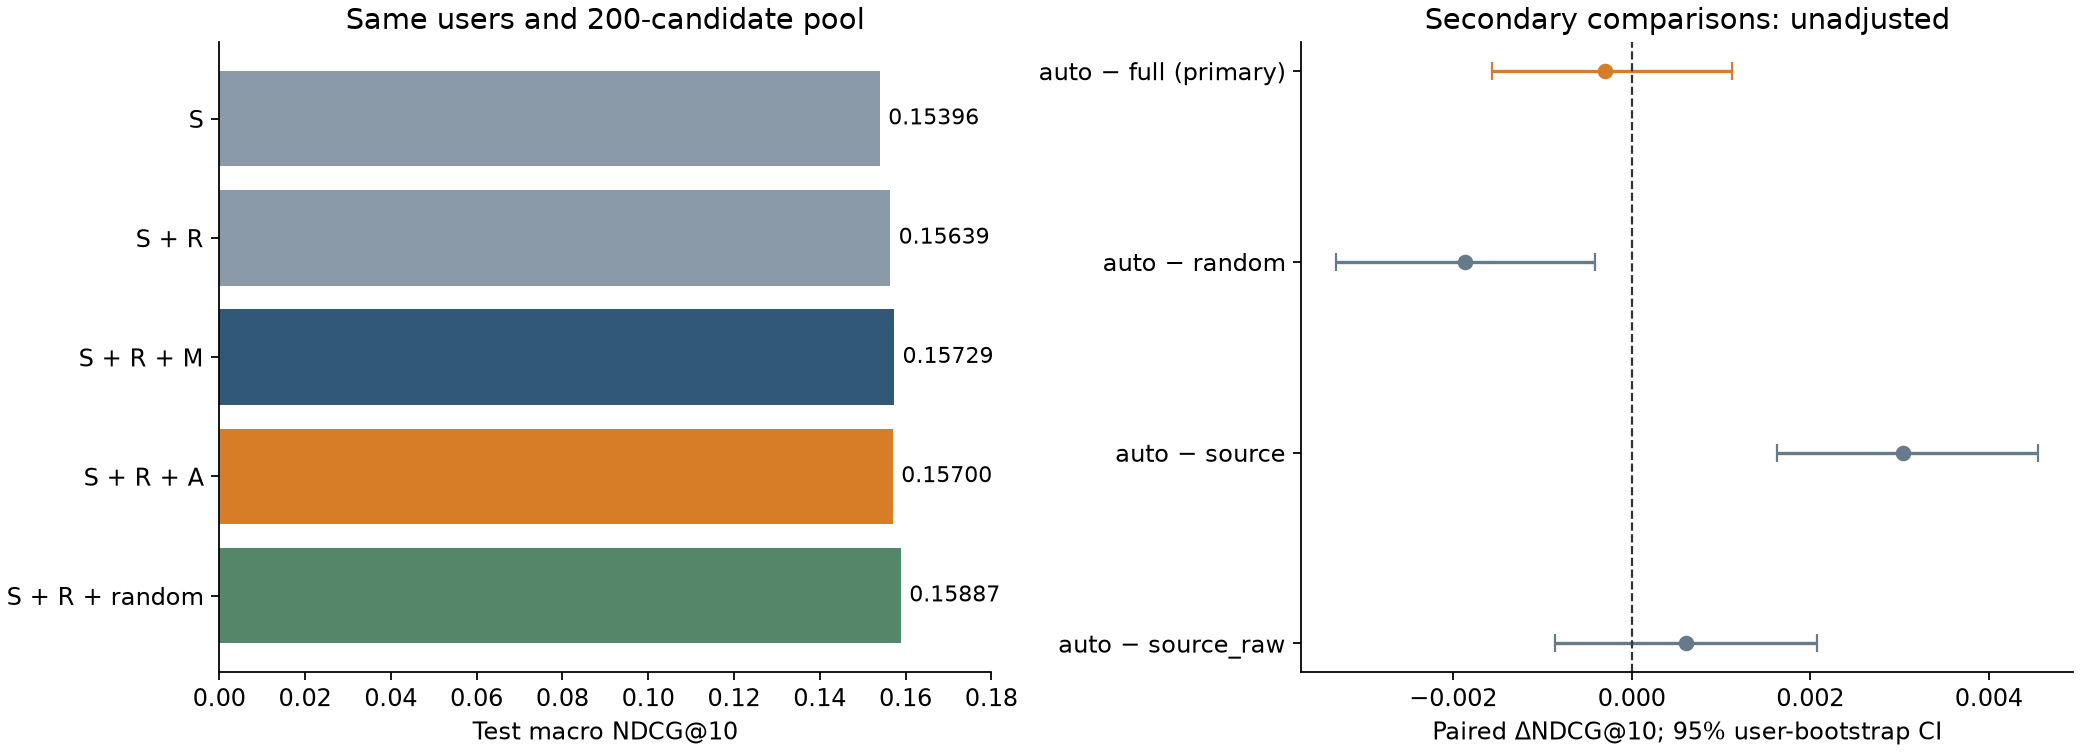

No established superiority or equivalence; selected A loses to one prespecified random control.


In [8]:
validation = pd.read_csv(D / 'validation_results.csv')
test = pd.read_csv(D / 'test_results.csv')
metrics = ['variant', 'ndcg@10', 'recall@10', 'map@10', 'candidate_recall@200', 'users']
display(validation[metrics])
display(test[metrics])
intervals = read(D / 'test_intervals.json')
contrasts = {'auto-full (primary)': intervals['primary_auto_minus_full']['ndcg@10']}
contrasts.update({'auto-' + n: v['ndcg@10'] for n, v in intervals['diagnostic_auto_minus'].items()})
display(pd.DataFrame(contrasts).T)
primary = contrasts['auto-full (primary)']
assert primary['lower'] <= 0 <= primary['upper']
assert contrasts['auto-random']['upper'] < 0
assert contrasts['auto-source_raw']['lower'] <= 0 <= contrasts['auto-source_raw']['upper']
display(Image(filename=str(D / 'report/test_comparison.png')))
print('No established superiority or equivalence; selected A loses to one prespecified random control.')

## Состав, сегменты и затраты

Выбраны в основном суммы duration и краткосрочные статистики фильма/демографии.
Один прямой аналог ручной формулы — genre share за 30 дней. Важность A=48.25%
не равна дополнительному качеству: коррелированные признаки делят важность.
Малый внутренний срез, корреляции и временная нестабильность — гипотезы
проигрыша random, не доказанные причины. Отсутствуют компонентные абляции.

Сегменты ниже описательные, без отдельных CI. Predict измеряет три прогретых
пакетных вызова на готовых признаках, без retrieval/генерации/Pool. Историческое
время fit full включает Pool и не является синхронным сравнением. 44 входа
вместо 82 не гарантируют экономию памяти: бинарная модель auto чуть больше full.

In [9]:
display(pd.read_csv(D / 'test_segments.csv'))
cost_rows = []
for name, model in record['models'].items():
    cost_rows.append({'variant': name, 'columns': len(model['identity']['columns']),
                      'pool_s': model.get('training_pool_seconds'), 'fit_s': model.get('fit_seconds'),
                      'predict_s': model['predict_seconds_median'], 'model_bytes': model['model_bytes']})
display(pd.DataFrame(cost_rows))
resources = []
for stage, audit_name in [('search', 'validation_verification'), ('validate', 'validation_verification'),
                          ('test', 'test_verification')]:
    resource = read(D / f'{audit_name}.json')['resources'][stage]
    resources.append({'stage': stage, 'seconds': resource['seconds'],
                      'peak_tree_rss_mib': resource['peak_tree_rss_mb'],
                      'over_limit': resource['memory_limit_exceeded']})
display(pd.DataFrame(resources))
assert not any(r['over_limit'] for r in resources)
print('Fixed-model comparisons only; no serving-latency or large-scale claim.')

,variant,segment,users,ndcg@10,recall@10,map@10
0,source,history_1_2,2688,0.198930,0.303112,0.143993
1,source,history_3_9,4321,0.166324,0.247039,0.116614
2,source,history_10_plus,4416,0.114487,0.160803,0.073554
3,source,retrieval_zero_hits,3123,0.000000,0.000000,0.000000
4,source,retrieval_some_hits,8302,0.211875,0.312254,0.146442
5,source_raw,history_1_2,2688,0.199313,0.300241,0.144957
6,source_raw,history_3_9,4321,0.169160,0.248946,0.119920
7,source_raw,history_10_plus,4416,0.117759,0.165593,0.075831
8,source_raw,retrieval_zero_hits,3123,0.000000,0.000000,0.000000
9,source_raw,retrieval_some_hits,8302,0.215215,0.314864,0.149686


,variant,columns,pool_s,fit_s,predict_s,model_bytes
0,auto,44,2.721681,1042.374118,0.494126,1319076
1,full,82,NaN,NaN,0.538951,1317352
2,random,44,2.964984,1040.202499,0.494937,1318612
3,source,13,0.222613,506.236428,0.404726,1256984
4,source_raw,28,2.682070,965.903198,0.451121,1316540


,stage,seconds,peak_tree_rss_mib,over_limit
0,search,576.420578,3288.625000,False
1,validate,3209.147729,3636.921875,False
2,test,3637.665378,3810.375000,False


Fixed-model comparisons only; no serving-latency or large-scale claim.


## Вывод и воспроизведение

Автоматический словарь даёт конкурентную точечную оценку, но выбранный отбор
не доказал пользу сверх случайного набора или прибавку NDCG к S+R на тесте.
Равенство с baseline не доказано. Для улучшений нужны несколько прошлых folds,
несколько random/seed и новый holdout; текущий тест нельзя снова использовать
для независимого подтверждения после настройки. Одна неделя, last-watch,
warm-active аудитория, статические метаданные и отсутствие экспозиций ограничивают вывод.

Полный отчёт: `RESEARCH_REPORT.md`, команды: `docs/automatic_features_usage.md`.
Проверка без обучения из корня проекта:
```bash
python -m pytest -q
python -m kion_autofeatures verify
python -m scripts.build_research_report
python -m scripts.build_research_notebook --execute
```
Полное повторение исследования после baseline: `python -m kion_autofeatures
reproduce --name reproduction_01` (новое имя). Оно обучает модели; этот ноутбук — только проверяет.

In [10]:
after = {str(p.relative_to(ROOT)): (sha256(p), p.stat().st_mtime_ns) for p in unchanged_paths}
assert before == after, 'Frozen method, saved models or fit receipts changed'
assert not fit_attempts
delivery_checks = {'fit_attempts': len(fit_attempts), 'frozen_seal': frozen['seal'],
                   'recomputed_real_feature_columns': len(auto_names),
                   'demo_user_id': demo_user, 'future_poison_passed': future_poison_passed,
                   'saved_models_and_fit_receipts_unchanged': before == after,
                   'demo_saved_predictions_match': demo_predictions_match,
                   'full_reload': reload_result}
print(json.dumps(delivery_checks, sort_keys=True))

{"demo_saved_predictions_match": true, "demo_user_id": 153, "fit_attempts": 0, "frozen_seal": "8aa5502a0eba5ec202350035db8243174d70c3f845901c27f37821c0a7c5e956", "full_reload": {"reload_verified": true, "test_evaluated": true, "verified": ["inputs", "search", "validation", "frozen", "test"]}, "future_poison_passed": true, "recomputed_real_feature_columns": 32, "saved_models_and_fit_receipts_unchanged": true}
